# Two routes to causal identification

This native Julia companion preserves the original public data, graphs, structural equations, sample sizes, seeds, repetitions, causal targets and decision rules. Fixed primitive NumPy streams retain the original random draws; Julia computes all generated outcomes, estimates and diagnostics. Native exceptions check the corresponding rejection conditions. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

The two-group, two-period difference-in-differences contrast is:

$$
\widehat\tau_{\mathrm{DID}}
=\left(\overline Y_{1,\mathrm{after}}-\overline Y_{1,\mathrm{before}}\right)
-\left(\overline Y_{0,\mathrm{after}}-\overline Y_{0,\mathrm{before}}\right).
$$

Here, group $1$ is the treated group, group $0$ is the comparison group, $\overline Y_{g,t}$ is the group mean at time $t$, and $\widehat\tau_{\mathrm{DID}}$ subtracts the comparison group's change from the treated group's change.

Row,Quantity,Value
,String,Int64
1,Rows,2500
2,Counties,500
3,First year,2003
4,Last year,2007
5,Treatment cohorts including never treated,4


Row,Cohort,Counties,Rows,Mean_log_employment
,String,Int64,Int64,Float64
1,Never treated,309,1545,5.63029
2,2004,20,100,6.09156
3,2006,40,200,6.54406
4,2007,131,655,5.82369


Row,year,2004,2006,2007,Never treated
,Int64,Float64,Float64,Float64,Float64
1,2003,6.1797,6.57399,5.84291,5.65463
2,2004,6.10656,6.51788,5.81078,5.592
3,2005,6.05945,6.52794,5.82087,5.60481
4,2006,6.0267,6.55743,5.82387,5.6389
5,2007,6.08539,6.54304,5.82005,5.66113


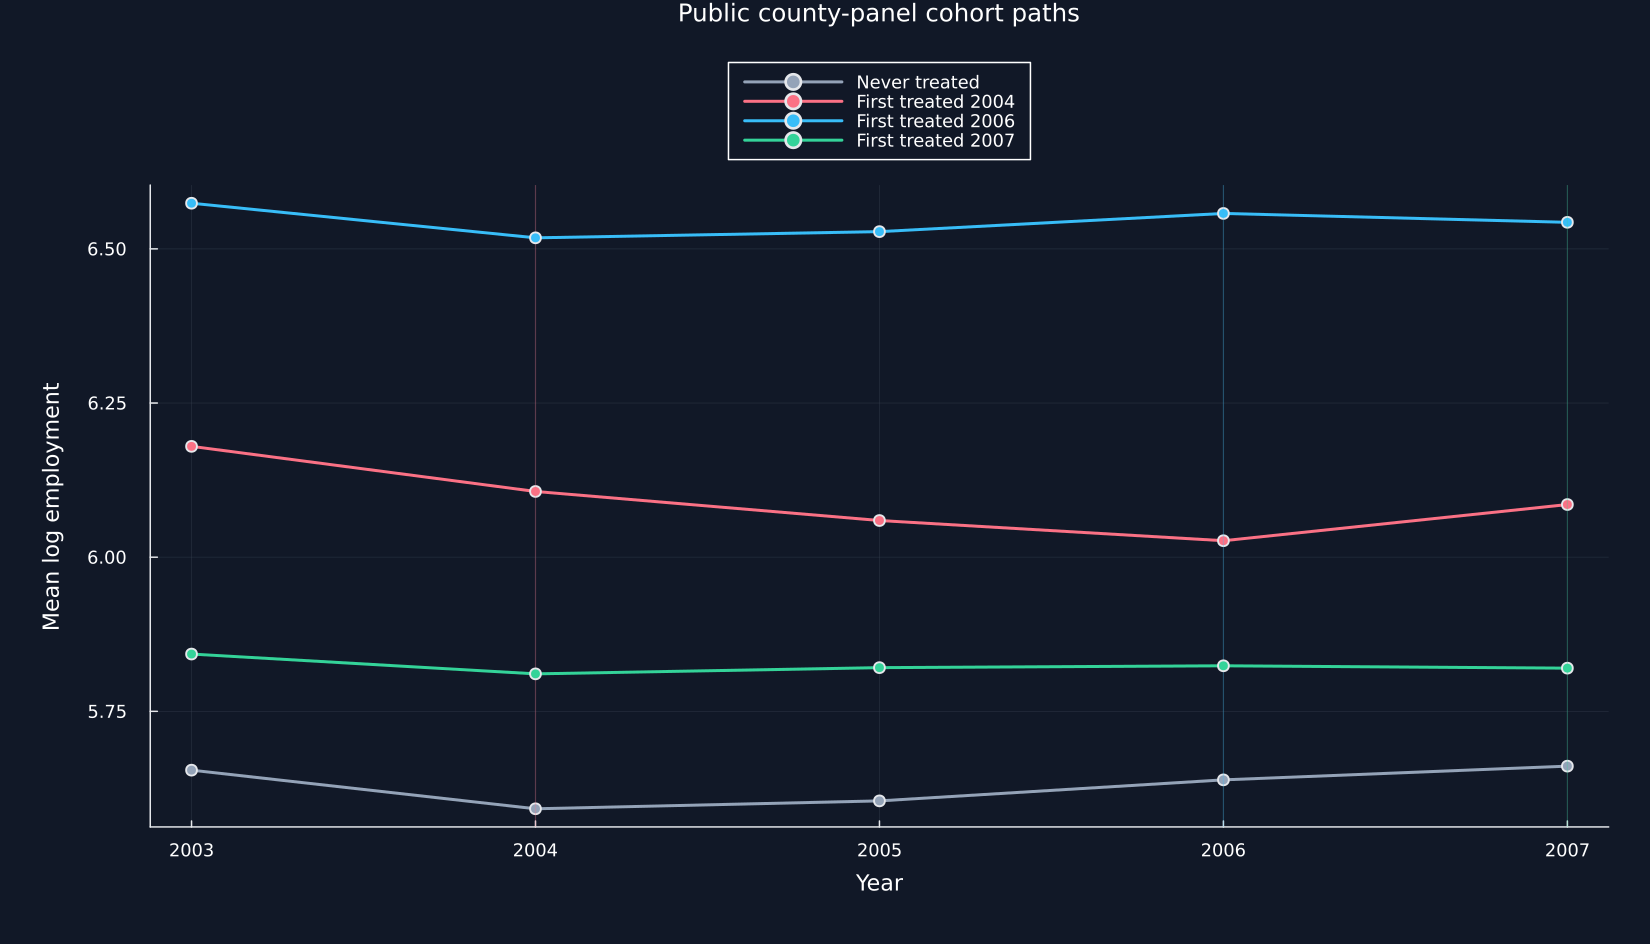

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("03_structural_treatment_effects");
using CSV, TOML
using RiskLabAI.CausalFactorAnalysis
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy
include(joinpath("..","support","BookTreatmentStudy.jl"))
using .BookTreatmentStudy
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
input_directory = joinpath("..","data","chapter03_random_inputs")
function table(values,name,caption)
    shown = copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column] = ifelse.(shown[!,column],"Yes","No")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter25-"*replace(name,"_"=>"-"))
    return nothing
end
function assert_artifacts(figures,tables)
    @assert all(name->isfile(joinpath(paths.figures,name*".pdf")),figures)
    @assert all(name->isfile(joinpath(paths.tables,name*".tex")),tables)
end
store = PrimitiveStore(input_directory,"did_iv")
data_path = dataset_path("mpdta")
panel = CSV.read(data_path,DataFrame)
panel_inventory = frame(["Quantity","Value"],[("Rows",nrow(panel)),("Counties",length(unique(panel.countyreal))),("First year",minimum(panel.year)),("Last year",maximum(panel.year)),("Treatment cohorts including never treated",length(unique(panel.first_treat)))])
cohorts,years = sort(unique(panel.first_treat)),sort(unique(panel.year))
cohort_name(cohort) = cohort==0 ? "Never treated" : string(cohort)
cohort_inventory = frame(["Cohort","Counties","Rows","Mean_log_employment"],[(cohort_name(cohort),length(unique(panel[panel.first_treat.==cohort,:countyreal])),sum(panel.first_treat.==cohort),mean(panel[panel.first_treat.==cohort,:lemp])) for cohort in cohorts])
cohort_means = frame(["year","first_treat","lemp","Cohort"],[(year,cohort,mean(panel[(panel.year.==year).&(panel.first_treat.==cohort),:lemp]),cohort_name(cohort)) for year in years for cohort in cohorts])
cohort_means_table = DataFrame(year=years)
for cohort in sort(cohorts;by=cohort_name)
    cohort_means_table[!,cohort_name(cohort)] = [mean(panel[(panel.year.==year).&(panel.first_treat.==cohort),:lemp]) for year in years]
end
table(panel_inventory,"mpdta_inventory","Inventory of the public county panel.")
table(cohort_inventory,"mpdta_cohort_inventory","Treatment-cohort counts in the public county panel.")
table(cohort_means_table,"mpdta_cohort_means","Mean log employment by year and first-treatment cohort.")
cohort_colors = Dict(0=>muted,2004=>palette.rose,2006=>palette.cyan,2007=>palette.green)
figure = plot(;xlabel="Year",ylabel="Mean log employment",title="Public county-panel cohort paths",xticks=(years,string.(years)),legend=:outertop,size=(1100,630))
for cohort in cohorts
    selected = cohort_means[cohort_means.first_treat.==cohort,:]
    plot!(figure,selected.year,selected.lemp;marker=:circle,color=cohort_colors[cohort],label=cohort==0 ? "Never treated" : "First treated "*string(cohort))
    cohort!=0 && vline!(figure,[cohort];color=cohort_colors[cohort],alpha=.28,linewidth=.8,label="")
end
save_figure(figure,paths,"mpdta_cohort_paths")
save_data(cohort_means,paths,"mpdta_cohort_paths");


## A descriptive public-data contrast

For a group first treated in year $g$, a group-time effect is written as:

$$
\operatorname{ATT}(g,t)
=\mathbb E\!\left[Y_t(1)-Y_t(0)\mid G=g\right].
$$

Here, $G$ is the first treatment year, $g$ is one treatment cohort, $t$ is the outcome year, $Y_t(1)$ is the treated potential outcome at time $t$, $Y_t(0)$ is its untreated counterpart, and $\operatorname{ATT}(g,t)$ is the average effect for cohort $g$ at time $t$.

Row,First-treatment cohort,Base year,Comparison year,Treated change,Never-treated change,Descriptive DID
,Int64,Int64,Int64,Float64,Float64,Float64
1,2004,2003,2004,-0.0731333,-0.06263,-0.0105032
2,2004,2003,2005,-0.120245,-0.0498216,-0.0704232
3,2004,2003,2006,-0.152992,-0.0157337,-0.137259
4,2004,2003,2007,-0.0943088,0.00650252,-0.100811
5,2006,2005,2006,0.0294932,0.0340878,-0.00459461
6,2006,2005,2007,0.0150996,0.0563241,-0.0412245
7,2007,2006,2007,-0.00381815,0.0222363,-0.0260544


Row,Cohort,Base year,Pre-treatment year,Placebo contrast
,Int64,Int64,Int64,Float64
1,2006,2003,2004,0.00652011
2,2006,2003,2005,0.00376929
3,2007,2003,2004,0.0305067
4,2007,2003,2005,0.0277808
5,2007,2003,2006,-0.00330636


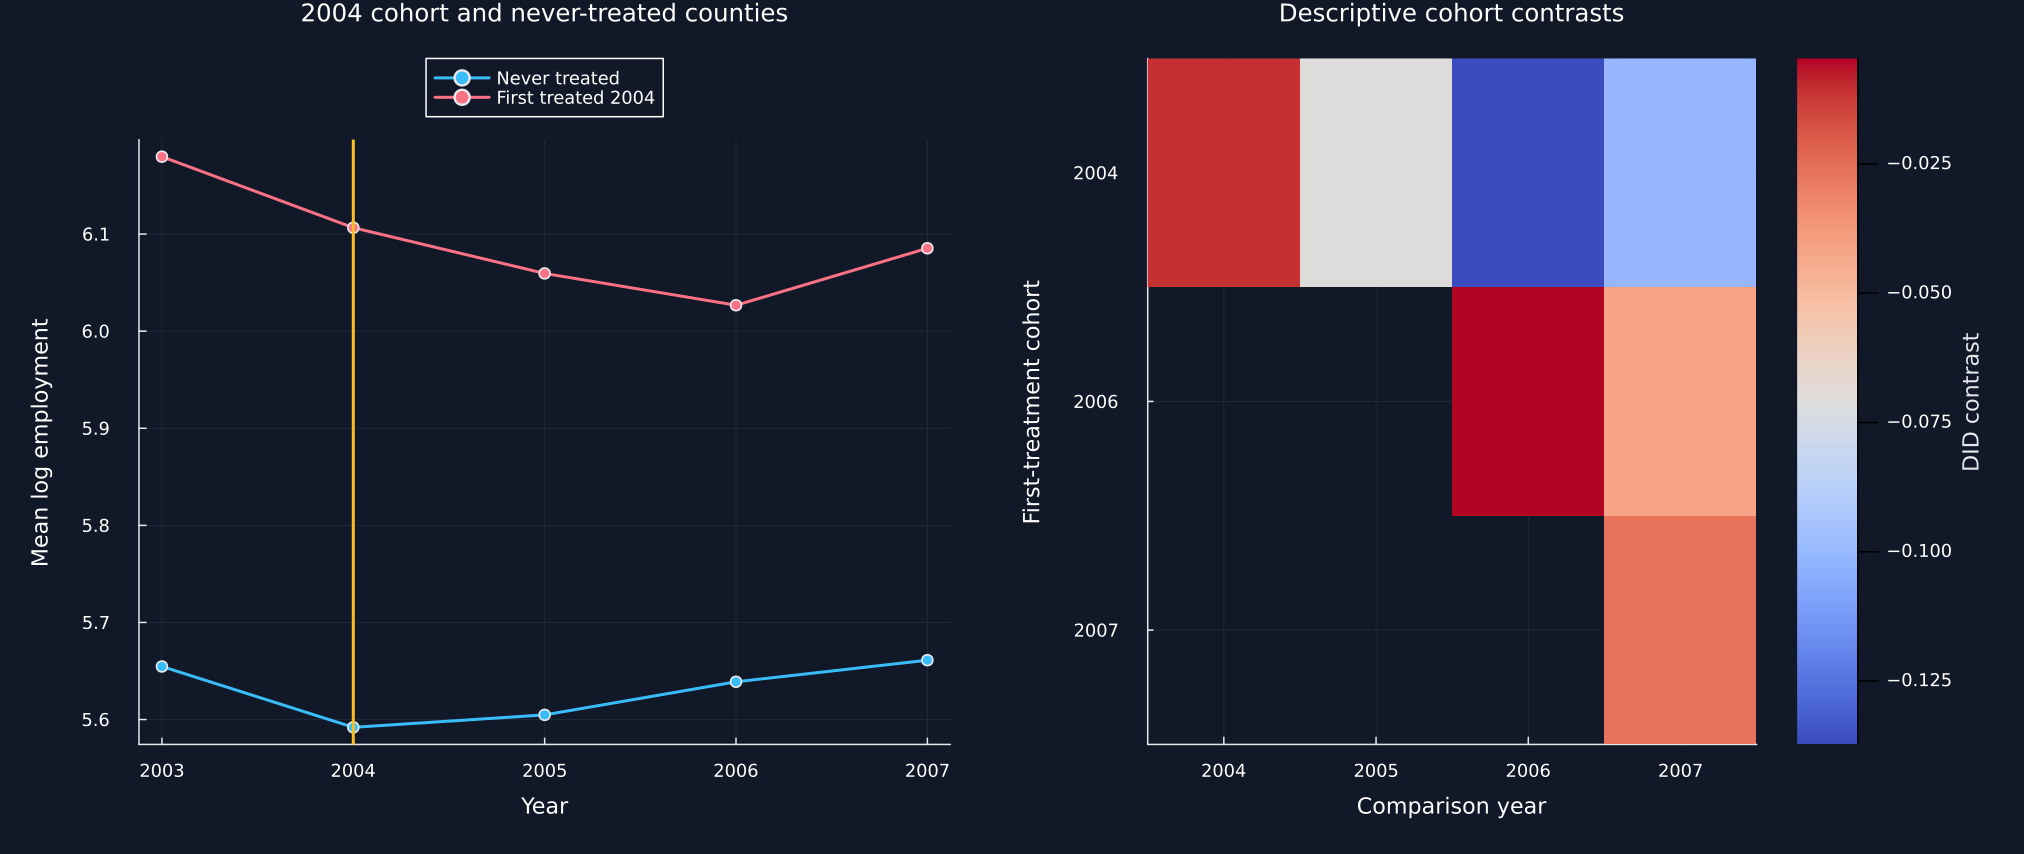

In [2]:
public_rows = Tuple[]
for cohort in [2004,2006,2007]
    before_year = cohort-1
    for after_year in cohort:2007
        treated_before = mean(panel[(panel.first_treat.==cohort).&(panel.year.==before_year),:lemp])
        treated_after = mean(panel[(panel.first_treat.==cohort).&(panel.year.==after_year),:lemp])
        control_before = mean(panel[(panel.first_treat.==0).&(panel.year.==before_year),:lemp])
        control_after = mean(panel[(panel.first_treat.==0).&(panel.year.==after_year),:lemp])
        result = difference_in_differences(treated_before,treated_after,control_before,control_after)
        push!(public_rows,(cohort,before_year,after_year,result.treated_change,result.control_change,result.estimate))
    end
end
public_did = frame(["First-treatment cohort","Base year","Comparison year","Treated change","Never-treated change","Descriptive DID"],public_rows)
main_public = public_did[(public_did[!,"First-treatment cohort"].==2004).&(public_did[!,"Comparison year"].==2004),:][1,:]
table(public_did,"mpdta_descriptive_did","Descriptive cohort changes relative to never-treated counties.")
public_pretrend_rows = Tuple[]
for cohort in [2006,2007],year in 2004:cohort-1
    treated_base = mean(panel[(panel.first_treat.==cohort).&(panel.year.==2003),:lemp])
    treated_year = mean(panel[(panel.first_treat.==cohort).&(panel.year.==year),:lemp])
    control_base = mean(panel[(panel.first_treat.==0).&(panel.year.==2003),:lemp])
    control_year = mean(panel[(panel.first_treat.==0).&(panel.year.==year),:lemp])
    placebo = difference_in_differences(treated_base,treated_year,control_base,control_year)
    push!(public_pretrend_rows,(cohort,2003,year,placebo.estimate))
end
public_pretrends = frame(["Cohort","Base year","Pre-treatment year","Placebo contrast"],public_pretrend_rows)
table(public_pretrends,"mpdta_pretrend_contrasts","Pre-treatment descriptive contrasts for later-treated cohorts.")
trajectory_panel = plot(;xlabel="Year",ylabel="Mean log employment",title="2004 cohort and never-treated counties",xticks=(years,string.(years)),legend=:outertop)
for (cohort,label,color) in [(0,"Never treated",palette.cyan),(2004,"First treated 2004",palette.rose)]
    selected = cohort_means[cohort_means.first_treat.==cohort,:]
    plot!(trajectory_panel,selected.year,selected.lemp;marker=:circle,color,label)
end
vline!(trajectory_panel,[2004];color=palette.amber,label="")
contrast_values = fill(NaN,3,4)
for row in eachrow(public_did)
    contrast_values[findfirst(==(row["First-treatment cohort"]),[2004,2006,2007]),row["Comparison year"]-2003] = row["Descriptive DID"]
end
contrast_panel = heatmap(1:4,1:3,contrast_values;xticks=(1:4,string.(2004:2007)),yticks=(1:3,string.([2004,2006,2007])),yflip=true,color=:coolwarm,xlabel="Comparison year",ylabel="First-treatment cohort",title="Descriptive cohort contrasts",colorbar_title="DID contrast")
save_figure(plot(trajectory_panel,contrast_panel;layout=(1,2),size=(1350,570)),paths,"mpdta_did_views")


## Testing controlled violations of parallel trends

The parallel-trends condition compares untreated changes across groups:

$$
\mathbb E[Y_{\mathrm{after}}(0)-Y_{\mathrm{before}}(0)\mid G=1]
=\mathbb E[Y_{\mathrm{after}}(0)-Y_{\mathrm{before}}(0)\mid G=0].
$$

Here, $Y_t(0)$ is the untreated potential outcome at time $t$, $G=1$ marks the treated group, $G=0$ marks the comparison group, and equality says their untreated mean changes would have been the same.

Row,Scenario,Treatment effect,Differential untreated trend,Anticipation,Expected DID,Estimated DID,Error from treatment effect
,String,Float64,Float64,Float64,Float64,Float64,Float64
1,Parallel trends,1.2,0.0,0.0,1.2,1.22588,0.0258796
2,Nonparallel untreated trends,1.2,0.6,0.0,1.8,1.77692,0.576918
3,Anticipation before treatment,1.2,0.0,0.4,0.8,0.789862,-0.410138
4,No treatment effect,0.0,0.0,0.0,0.0,-0.0441929,-0.0441929


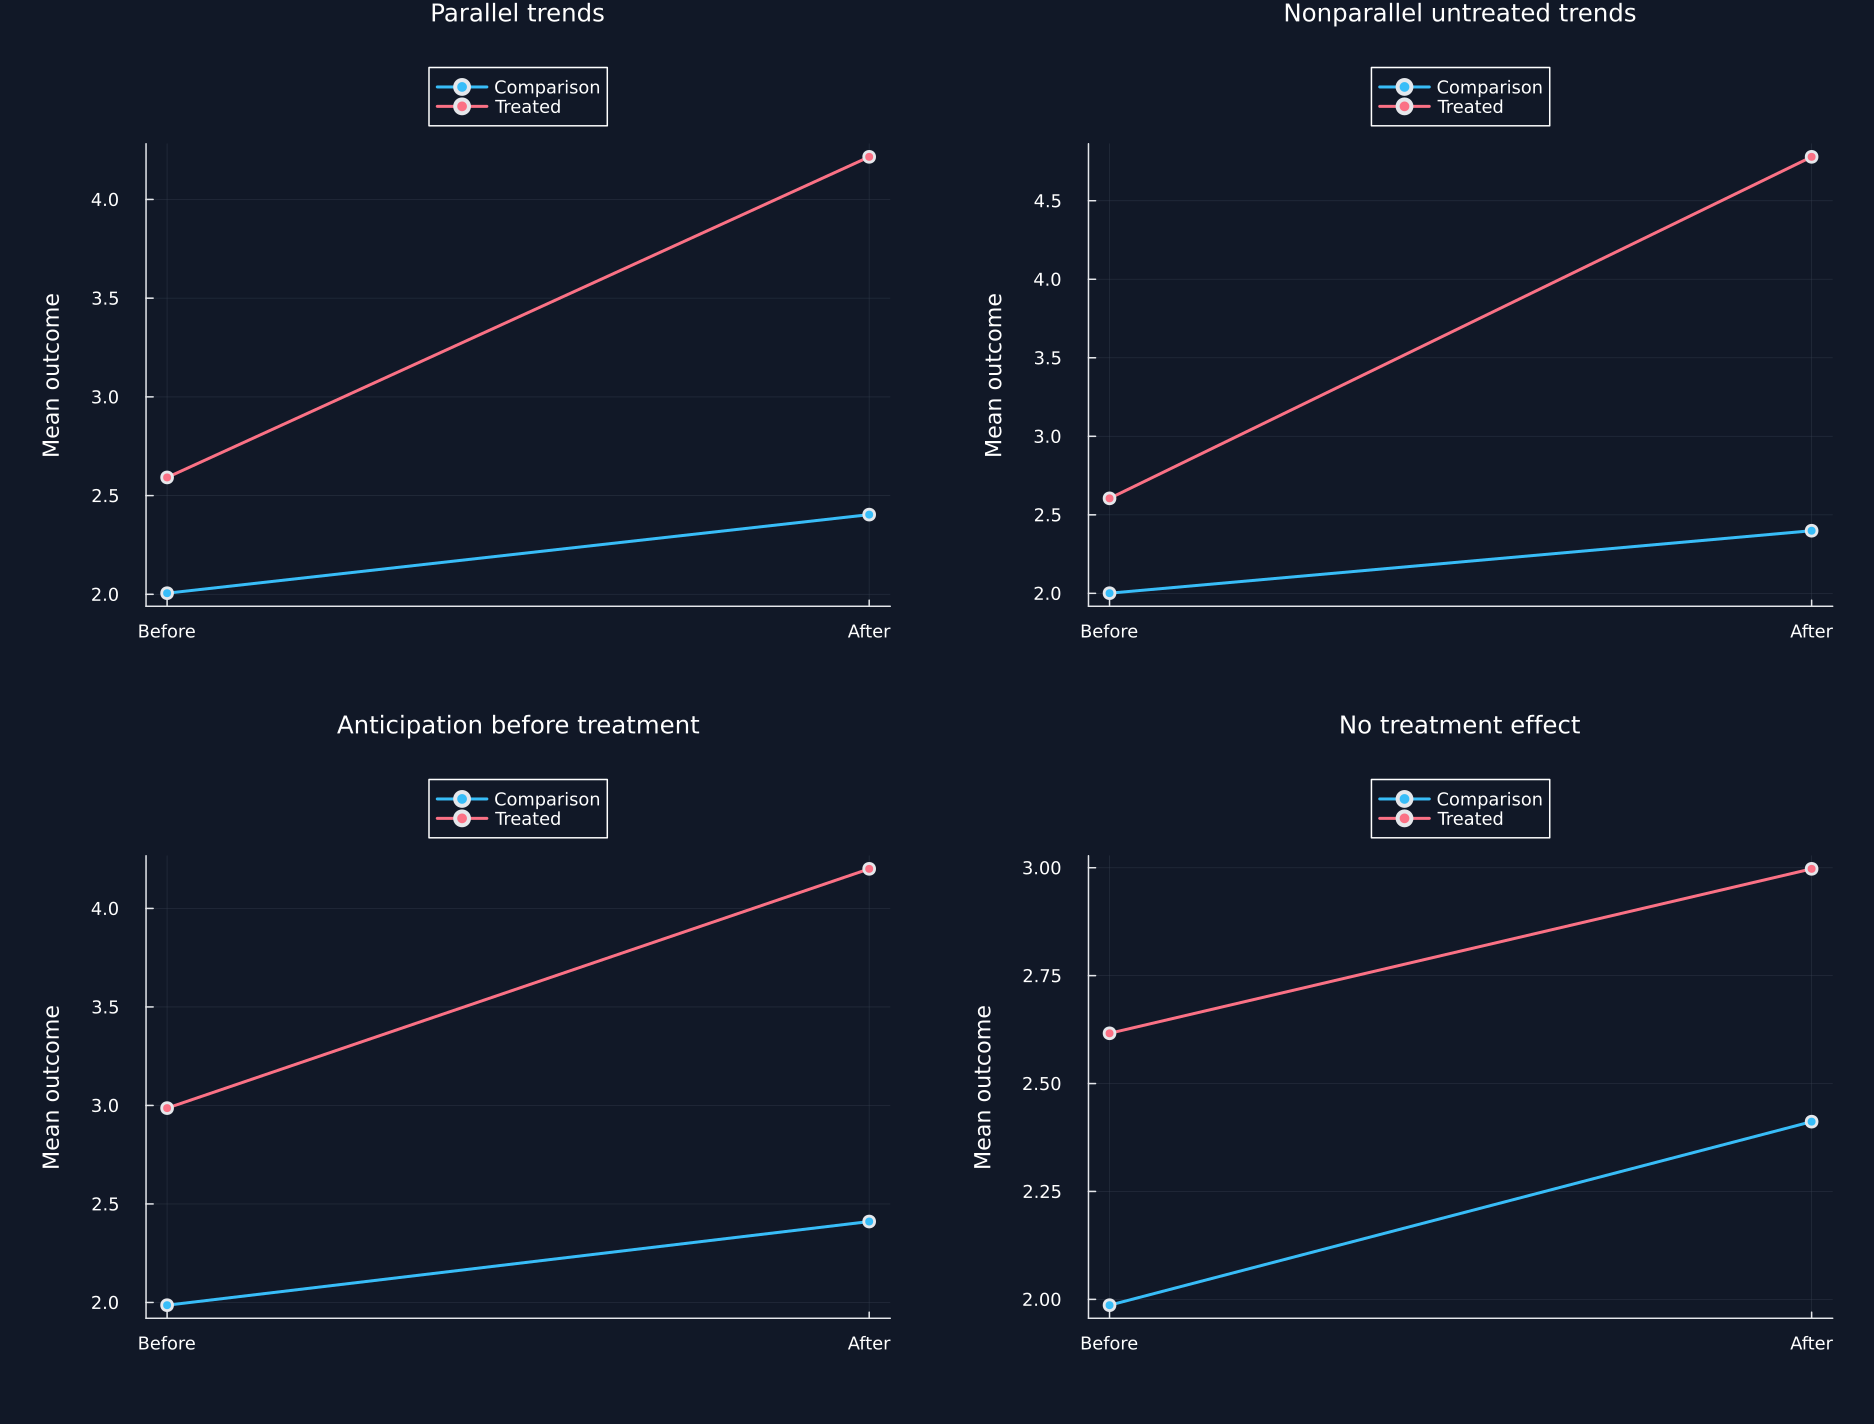

Row,Scenario,Known treatment effect,Expected DID,Mean estimate,Bias from treatment effect,Root mean squared error from treatment effect,Standard deviation
,String,Float64,Float64,Float64,Float64,Float64,Float64
1,Parallel trends,1.2,1.2,1.20052,0.000517645,0.0979432,0.0980399
2,Nonparallel untreated trends,1.2,1.8,1.80226,0.602261,0.610565,0.100459
3,Anticipation before treatment,1.2,0.8,0.799695,-0.400305,0.413733,0.104656


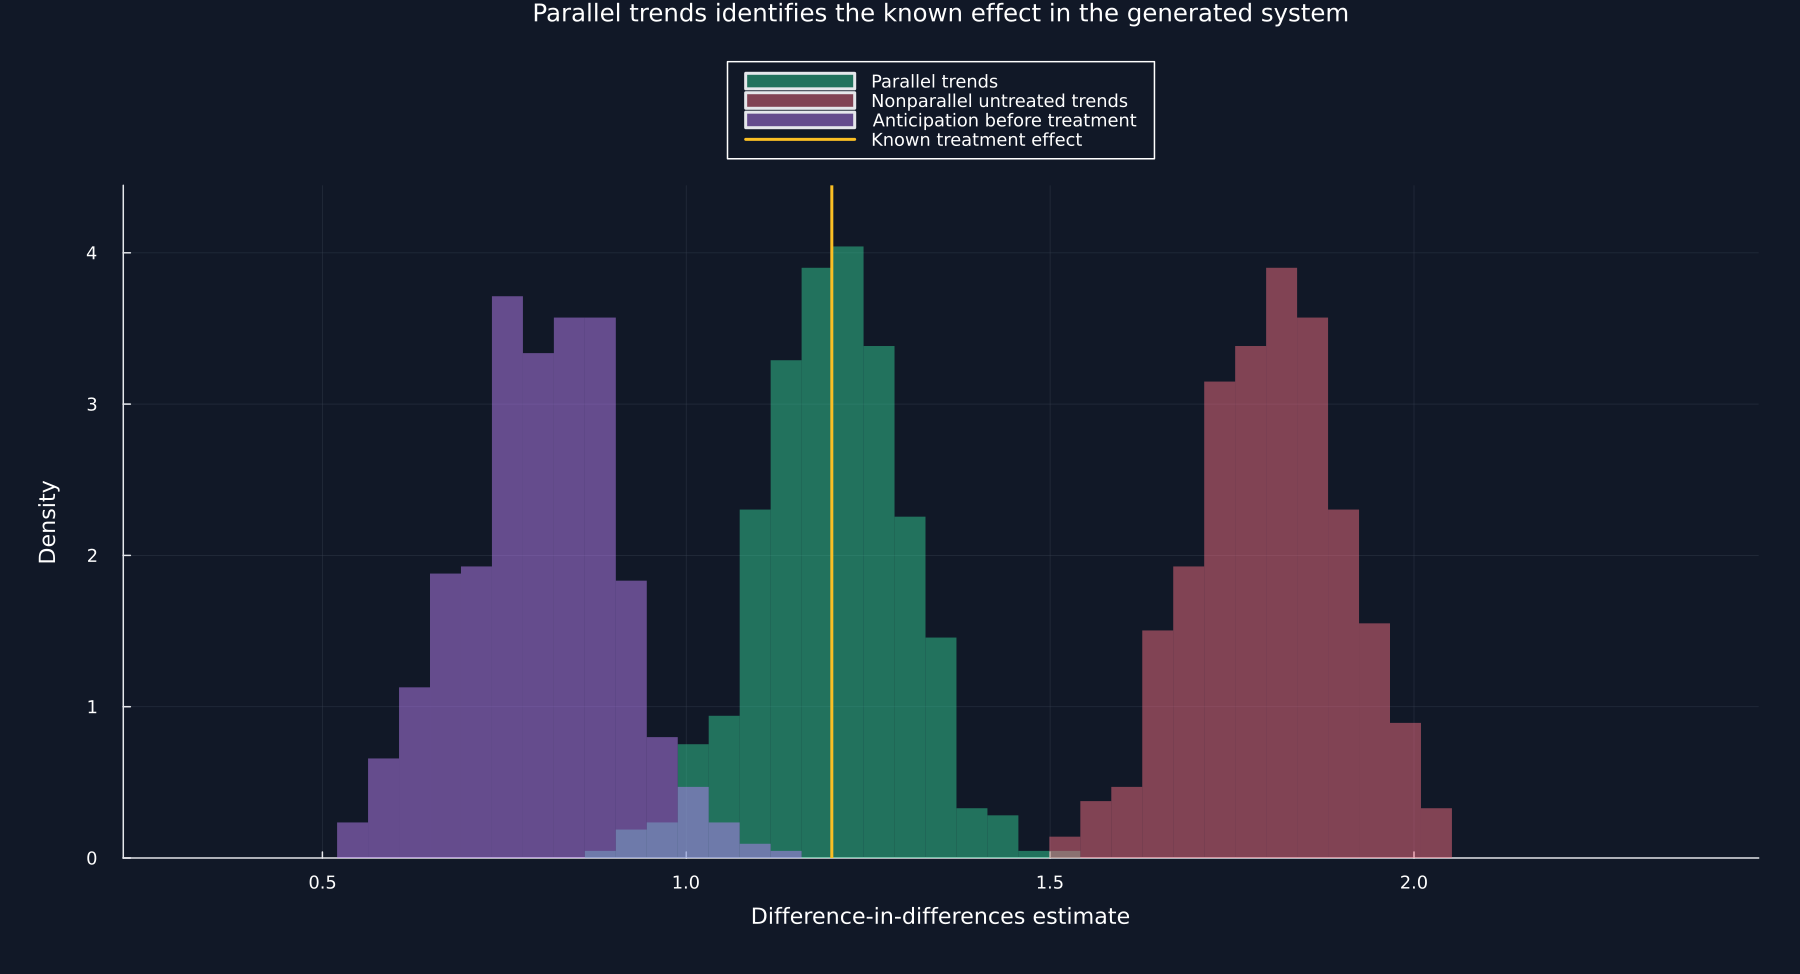

In [3]:
scenario_specs = [("Parallel trends",1.2,0.,0.),("Nonparallel untreated trends",1.2,.6,0.),("Anticipation before treatment",1.2,0.,.4),("No treatment effect",0.,0.,0.)]
scenario_rows = Tuple[]
scenario_frames = Dict{String,DataFrame}()
for (index,(name,effect,differential,anticipation)) in enumerate(scenario_specs)
    result,values = generated_did(store,"did_demo",index,effect;differential_trend=differential,anticipation)
    scenario_frames[name] = values
    push!(scenario_rows,(name,effect,differential,anticipation,effect+differential-anticipation,result.estimate,result.estimate-effect))
    save_data(values,paths,"generated_did_sample_"*string(index))
end
generated_did_scenarios = frame(["Scenario","Treatment effect","Differential untreated trend","Anticipation","Expected DID","Estimated DID","Error from treatment effect"],scenario_rows)
table(generated_did_scenarios,"generated_did_scenarios","Difference-in-differences under controlled assumptions and failures.")
panels = Plots.Plot[]
for (name,_,_,_) in scenario_specs
    values = scenario_frames[name]
    panel_plot = plot(;title=name,xticks=([0,1],["Before","After"]),ylabel="Mean outcome",legend=:outertop)
    for (group_value,label,color) in [(0,"Comparison",palette.cyan),(1,"Treated",palette.rose)]
        means = [mean(values[values.Group.==group_value,column]) for column in ["Before","After"]]
        plot!(panel_plot,[0,1],means;marker=:circle,color,label)
    end
    push!(panels,panel_plot)
end
save_figure(plot(panels...;layout=(2,2),size=(1250,950)),paths,"generated_did_scenario_paths")
repeated_rows,repeated_records = Tuple[],Tuple[]
repeated_values = Pair{String,Vector{Float64}}[]
for (scenario_index,(name,effect,differential,anticipation)) in enumerate(scenario_specs[1:3])
    estimates = Float64[]
    for repetition in 1:500
        result,_ = generated_did(store,"did_"*string(scenario_index-1),repetition,effect;differential_trend=differential,anticipation)
        push!(estimates,result.estimate)
        push!(repeated_records,(name,repetition-1,result.treated_change,result.control_change,result.estimate))
    end
    push!(repeated_values,name=>estimates)
    push!(repeated_rows,(name,effect,effect+differential-anticipation,mean(estimates),mean(estimates)-effect,sqrt(mean(abs2,estimates.-effect)),std(estimates)))
end
did_repeated_summary = frame(["Scenario","Known treatment effect","Expected DID","Mean estimate","Bias from treatment effect","Root mean squared error from treatment effect","Standard deviation"],repeated_rows)
table(did_repeated_summary,"did_repeated_summary","Repeated difference-in-differences estimates under three scenarios.")
save_data(frame(["Scenario","Repetition","Treated change","Control change","Estimate"],repeated_records),paths,"did_repetitions")
bins = collect(range(.35,2.35;length=48))
peak = maximum(histogram_peak(values,bins;density=true) for (_,values) in repeated_values)
figure = plot(;xlabel="Difference-in-differences estimate",ylabel="Density",title="Parallel trends identifies the known effect in the generated system",ylims=(0,1.1peak),legend=:outertop,size=(1200,650))
for ((name,values),color) in zip(repeated_values,[palette.green,palette.rose,violet])
    histogram!(figure,values;bins,normalize=:pdf,alpha=.48,color,linealpha=0,label=name)
end
vline!(figure,[1.2];color=palette.amber,label="Known treatment effect")
save_figure(figure,paths,"did_repeated_distributions")


## Instrumental-variable covariance ratio

With one valid instrument, the linear effect is represented by the covariance ratio:

$$
\beta_{\mathrm{IV}}
=\frac{\operatorname{Cov}(Z,Y)}{\operatorname{Cov}(Z,X)}.
$$

Here, $Z$ is the instrument, $X$ is treatment, $Y$ is outcome, $\operatorname{Cov}$ denotes covariance, and $\beta_{\mathrm{IV}}$ is the identified linear effect when relevance, exclusion, and outside variation hold.

Row,Outcome-instrument covariance,Treatment-instrument covariance,Instrumental effect
,Float64,Float64,Float64
1,0.9,0.3,3.0
2,-2.0,0.5,-4.0


Row,Scenario,Relevance,Direct outcome path,Known treatment effect,Mean estimate,Median estimate,Bias,Root mean squared error,Middle 95 percent width
,String,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,Strong valid instrument,1.0,0.0,0.8,0.799377,0.803424,-0.00062264,0.0479394,0.184608
2,Weak valid instrument,0.08,0.0,0.8,1.24847,0.829259,0.448474,5.24658,3.4419
3,Strong instrument with direct outcome path,1.0,0.7,0.8,1.50116,1.50257,0.701158,0.702323,0.158456


Row,Scenario,Median_denominator,Smallest_absolute_denominator,Median_estimate
,String,Float64,Float64,Float64
1,Strong instrument with direct outcome path,0.9978,0.850431,1.50374
2,Strong valid instrument,1.00115,0.855883,0.8029
3,Weak valid instrument,0.0840813,0.000886047,0.888193


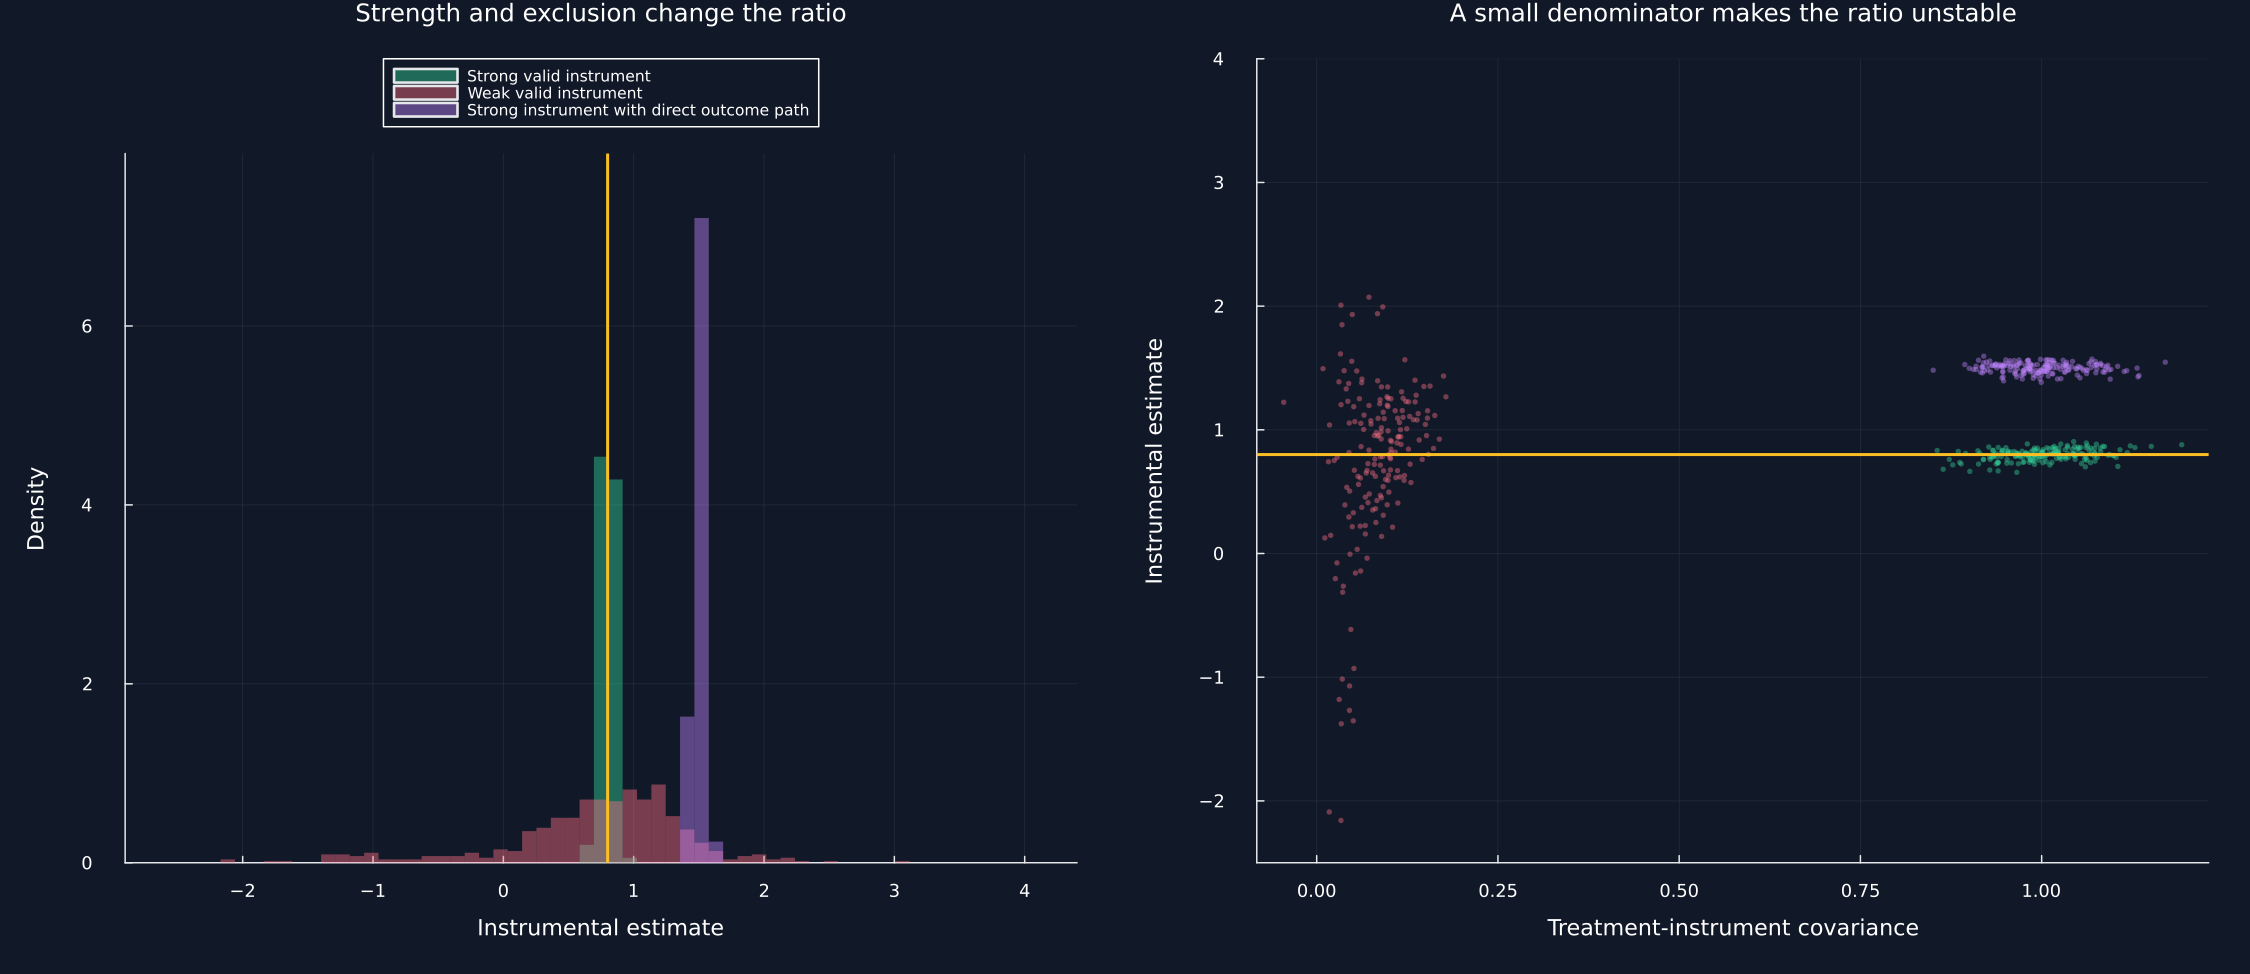

In [4]:
exact_iv = linear_instrumental_variable_effect(.9,.3)
exact_iv_table = frame(["Outcome-instrument covariance","Treatment-instrument covariance","Instrumental effect"],[(.9,.3,exact_iv),(-2.,.5,linear_instrumental_variable_effect(-2.,.5))])
table(exact_iv_table,"iv_exact_ratios","Exact covariance-ratio calculations.")
iv_specs = [("Strong valid instrument",1.,0.),("Weak valid instrument",.08,0.),("Strong instrument with direct outcome path",1.,.7)]
iv_rows,iv_records,cloud_rows = Tuple[],Tuple[],Tuple[]
iv_estimates = Pair{String,Vector{Float64}}[]
for (scenario_index,(name,relevance,exclusion_path)) in enumerate(iv_specs)
    estimates = Float64[]
    for repetition in 1:500
        estimate,numerator,denominator = generated_iv(store,"iv_"*string(scenario_index-1),repetition,relevance;exclusion_path)
        push!(estimates,estimate)
        push!(iv_records,(name,repetition-1,numerator,denominator,estimate))
        repetition<=180 && push!(cloud_rows,(name,denominator,estimate))
    end
    push!(iv_estimates,name=>estimates)
    push!(iv_rows,(name,relevance,exclusion_path,.8,mean(estimates),median(estimates),mean(estimates)-.8,sqrt(mean(abs2,estimates.-.8)),quantile(estimates,.975)-quantile(estimates,.025)))
end
iv_simulation_summary = frame(["Scenario","Relevance","Direct outcome path","Known treatment effect","Mean estimate","Median estimate","Bias","Root mean squared error","Middle 95 percent width"],iv_rows)
iv_covariance_cloud = frame(["Scenario","Treatment-instrument covariance","Instrumental estimate"],cloud_rows)
covariance_summary_rows = Tuple[]
for name in sort(unique(iv_covariance_cloud.Scenario))
    values = iv_covariance_cloud[iv_covariance_cloud.Scenario.==name,:]
    push!(covariance_summary_rows,(name,median(values[!,"Treatment-instrument covariance"]),minimum(abs,values[!,"Treatment-instrument covariance"]),median(values[!,"Instrumental estimate"])))
end
iv_covariance_summary = frame(["Scenario","Median_denominator","Smallest_absolute_denominator","Median_estimate"],covariance_summary_rows)
table(iv_simulation_summary,"iv_simulation_summary","Instrumental-variable behavior under strength and exclusion changes.")
table(iv_covariance_summary,"iv_covariance_summary","Covariance denominators and estimates in the generated instrument study.")
save_data(frame(["Scenario","Repetition","Outcome-instrument covariance","Treatment-instrument covariance","Estimate"],iv_records),paths,"iv_repetitions")
save_data(iv_covariance_cloud,paths,"iv_covariance_cloud")
clipped_range = (-2.5,4.)
bins = collect(range(clipped_range...;length=60))
visible_values = [filter(value->clipped_range[1]<=value<=clipped_range[2],values) for (_,values) in iv_estimates]
peak = maximum(histogram_peak(values,bins;density=true) for values in visible_values)
ratio_panel = plot(;xlabel="Instrumental estimate",ylabel="Density",title="Strength and exclusion change the ratio",ylims=(0,1.1peak),legend=:outertop,legendfontsize=7)
cloud_panel = plot(;xlabel="Treatment-instrument covariance",ylabel="Instrumental estimate",title="A small denominator makes the ratio unstable",ylims=clipped_range,legend=false)
for ((name,_),values,color) in zip(iv_estimates,visible_values,[palette.green,palette.rose,violet])
    histogram!(ratio_panel,values;bins,normalize=:pdf,color,alpha=.44,linealpha=0,label=name)
    cloud = iv_covariance_cloud[iv_covariance_cloud.Scenario.==name,:]
    scatter!(cloud_panel,cloud[!,"Treatment-instrument covariance"],cloud[!,"Instrumental estimate"];color,markersize=2,markeralpha=.42,markerstrokewidth=0,label="")
end
vline!(ratio_panel,[.8];color=palette.amber,label="")
hline!(cloud_panel,[.8];color=palette.amber,label="")
save_figure(plot(ratio_panel,cloud_panel;layout=(1,2),size=(1500,650)),paths,"iv_strength_and_exclusion")


## What the comparisons establish

In [5]:
did_iv_checks = frame(["Check","Expected result","Observed result","Passed"],[contract_result("Nonfinite DID input",()->difference_in_differences(0.,1.,0.,Inf),ArgumentError),contract_result("Zero IV denominator",()->linear_instrumental_variable_effect(1.,0.),ArgumentError),contract_result("Nonfinite IV numerator",()->linear_instrumental_variable_effect(NaN,1.),ArgumentError)])
did_iv_summary = frame(["Question","Answer"],[["Does a pre-trend check prove parallel trends?","No"],["Is a two-period DID enough for every staggered design?","No"],["Does instrument strength prove exclusion?","No"],["Why retain generated checks?","They reveal truth and controlled failures"],["How is the public panel used?","As a descriptive real-data illustration"]])
table(did_iv_checks,"did_iv_input_checks","Input checks for difference-in-differences and instrumental-variable calculations.")
table(did_iv_summary,"did_iv_section_summary","Main conclusions from the panel and instrument experiments.")


Row,Check,Expected result,Observed result,Passed
,String,String,String,String
1,Nonfinite DID input,Rejected,Rejected,Yes
2,Zero IV denominator,Rejected,Rejected,Yes
3,Nonfinite IV numerator,Rejected,Rejected,Yes


Row,Question,Answer
,String,String
1,Does a pre-trend check prove parallel trends?,No
2,Is a two-period DID enough for every staggered design?,No
3,Does instrument strength prove exclusion?,No
4,Why retain generated checks?,They reveal truth and controlled failures
5,How is the public panel used?,As a descriptive real-data illustration


## Tests

In [6]:
@assert size(panel)==(2500,6)
@assert length(unique(panel.countyreal))==500
@assert Set(unique(panel.year))==Set(2003:2007)
@assert main_public["Descriptive DID"]≈-.01050324622096177
@assert abs(generated_did_scenarios[1,"Estimated DID"]-1.2)<.08
@assert generated_did_scenarios[2,"Error from treatment effect"]>.50
@assert generated_did_scenarios[3,"Error from treatment effect"]<-.30
@assert abs(did_repeated_summary[1,"Mean estimate"]-1.2)<.04
@assert exact_iv==3.
@assert abs(iv_simulation_summary[1,"Mean estimate"]-.8)<.04
@assert iv_simulation_summary[2,"Root mean squared error"]>iv_simulation_summary[1,"Root mean squared error"]*3
@assert iv_simulation_summary[3,"Bias"]>.60
@assert all(did_iv_checks.Passed)
assert_artifacts(["mpdta_cohort_paths","mpdta_did_views","generated_did_scenario_paths","did_repeated_distributions","iv_strength_and_exclusion"],["mpdta_inventory","mpdta_cohort_inventory","mpdta_cohort_means","mpdta_descriptive_did","mpdta_pretrend_contrasts","generated_did_scenarios","did_repeated_summary","iv_exact_ratios","iv_simulation_summary","iv_covariance_summary","did_iv_input_checks","did_iv_section_summary"])
nothing
